# Prever eventos de anomalias nos datasets de taxi

***Deteção de anomalias não supervisionadas em dados do tipo timeseries com algoritmos de Random Cut Forest.***

# Introdução
***

Amazon SageMaker Random Cut Forest (RCF) é um algoritmo para detectar anomalias em dataset. Examples: a) detectar uso do site fora do padrao, b) detectar sensores que estão fora do padrão, ou c) quando mudanças no transito refletem em ocorrencias especiais. 

Neste dataset do período de 6 meses identificaremos anomalias como a maratona de NYC, Ações de Graças, Natal, Ano novo, ou dias de nevasca de neve.

In [1]:
import boto3
import botocore
import sagemaker
import sys


bucket = 'alexbc.datalake'
prefix = 'machine-learning-models/sagemaker/rcf-benchmarks'
execution_role = sagemaker.get_execution_role()

boto3.Session().client('s3').head_bucket(Bucket=bucket)
print('Training input/output sera armazenado no s3://{}/{}'.format(bucket, prefix))

Training input/output sera armazenado no s3://alexbc.datalake/machine-learning-models/sagemaker/rcf-benchmarks


In [2]:
%%time

import pandas as pd
import urllib.request

data_filename = 'passengers_by_halfhour.csv'
data_source = 'https://s3.amazonaws.com/alexbc.datalake/ny-taxi-data/taxi_datamart/' + data_filename
urllib.request.urlretrieve(data_source, data_filename)
taxi_data = pd.read_csv(data_filename, delimiter=',')

CPU times: user 20 ms, sys: 4 ms, total: 24 ms
Wall time: 85 ms


## Análise exploratória

In [3]:
taxi_data.head()

,timestamp,value
0,2014-07-01 00:00:00,10844
1,2014-07-01 00:30:00,8127
2,2014-07-01 01:00:00,6210
3,2014-07-01 01:30:00,4656
4,2014-07-01 02:00:00,3820


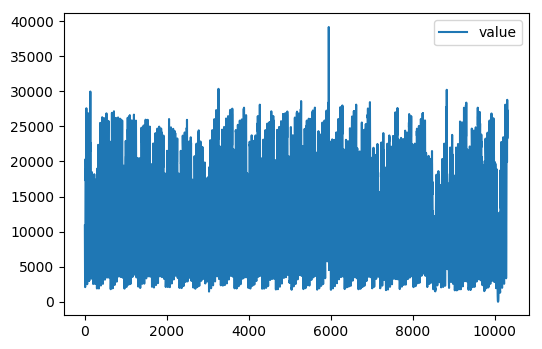

In [4]:
%matplotlib inline

import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['figure.dpi'] = 100

taxi_data.plot()

In [5]:
taxi_data[5952:6000]

,timestamp,value
5952,2014-11-02 00:00:00,25110
5953,2014-11-02 00:30:00,23109
5954,2014-11-02 01:00:00,39197
5955,2014-11-02 01:30:00,35212
5956,2014-11-02 02:00:00,13259
5957,2014-11-02 02:30:00,12250
5958,2014-11-02 03:00:00,10013
5959,2014-11-02 03:30:00,7898
5960,2014-11-02 04:00:00,6375
5961,2014-11-02 04:30:00,4532


## Converter o formato para um formato aceitável pelo Random Cut Forest (RecordIO)

In [6]:
def convert_and_upload_training_data(ndarray, bucket, prefix, filename='data.pbr'):
    import boto3
    import os
    from sagemaker.amazon.common import numpy_to_record_serializer
    
    # convert numpy array to Protobuf RecordIO format
    serializer = numpy_to_record_serializer()
    buffer = serializer(ndarray)
    
    # Upload to S3
    s3_object = os.path.join(prefix, 'train', filename)
    boto3.Session().resource('s3').Bucket(bucket).Object(s3_object).upload_fileobj(buffer)
    
    s3_path = 's3://{}/{}'.format(bucket, s3_object)
    return s3_path


# RCV only works on an array of values.
s3_train_data = convert_and_upload_training_data(
    taxi_data.value.as_matrix().reshape(-1,1),
    bucket,
    prefix)
print('Uploaded para {}'.format(s3_train_data))

/home/ec2-user/anaconda3/envs/python3/lib/python3.6/site-packages/ipykernel/__main__.py:20: FutureWarning: Method .as_matrix will be removed in a future version. Use .values instead.


Uploaded para s3://alexbc.datalake/machine-learning-models/sagemaker/rcf-benchmarks/train/data.pbr


# Treino

***


In [2]:
import boto3

# select the algorithm container based on this notebook's current location
containers = {'us-west-2': '174872318107.dkr.ecr.us-west-2.amazonaws.com/randomcutforest:latest',
              'us-east-1': '382416733822.dkr.ecr.us-east-1.amazonaws.com/randomcutforest:latest',
              'us-east-2': '404615174143.dkr.ecr.us-east-2.amazonaws.com/randomcutforest:latest',
              'eu-west-1': '438346466558.dkr.ecr.eu-west-1.amazonaws.com/randomcutforest:latest',
              'ap-northeast-1': '351501993468.dkr.ecr.ap-northeast-1.amazonaws.com/randomcutforest:latest'}
region_name = boto3.Session().region_name
container = containers[region_name]

print('Container do RCF que esta sendo utilizado: {} ({})'.format(container, region_name))

Container do RCF que esta sendo utilizado: 382416733822.dkr.ecr.us-east-1.amazonaws.com/randomcutforest:latest (us-east-1)


## Hyperparametros

In [8]:
session = sagemaker.Session()

# informações gerais do job
rcf = sagemaker.estimator.Estimator(
    container,
    execution_role,
    output_path='s3://{}/{}/output'.format(bucket, prefix),
    train_instance_count=1,
    train_instance_type='ml.m4.xlarge',
    sagemaker_session=session,
)

# principais hyperparameterer como numero de amostras da arvore, numero da arvore
rcf.set_hyperparameters(
    num_samples_per_tree = 200,
    num_trees = 50,
    feature_dim = 1,
)

s3_train_input = sagemaker.session.s3_input(
    s3_train_data,
    distribution='ShardedByS3Key',
    content_type='application/x-recordio-protobuf',
)

# run the training job on input data stored in S3
rcf.fit({'train': s3_train_input})

INFO:sagemaker:Creating training-job with name: randomcutforest-2018-06-21-12-28-07-694


.......................
Docker entrypoint called with argument(s): train
[06/21/2018 12:31:48 INFO 140498284369728] Reading default configuration from /opt/amazon/lib/python2.7/site-packages/algorithm/resources/default-conf.json: {u'num_samples_per_tree': 256, u'_tuning_objective_metric': u'', u'_num_gpus': u'auto', u'_log_level': u'info', u'_kvstore': u'dist_async', u'force_dense': u'true', u'epochs': 1, u'num_trees': 100, u'eval_metrics': [u'accuracy', u'precision_recall_fscore'], u'_num_kv_servers': u'auto', u'mini_batch_size': 1000}
[06/21/2018 12:31:48 INFO 140498284369728] Reading provided configuration from /opt/ml/input/config/hyperparameters.json: {u'feature_dim': u'1', u'num_samples_per_tree': u'200', u'num_trees': u'50'}
[06/21/2018 12:31:48 INFO 140498284369728] Final configuration: {u'num_samples_per_tree': u'200', u'_tuning_objective_metric': u'', u'_num_gpus': u'auto', u'_log_level': u'info', u'_kvstore': u'dist_async', u'force_dense': u'true', u'epochs': 1, u'feature_di

===== Job Complete =====
Billable seconds: 124


In [9]:
print('Nome do job de treino: {}'.format(rcf.latest_training_job.job_name))

Nome do job de treino: randomcutforest-2018-06-21-12-28-07-694


# Deploy da infra dos modelos para Inferencia

In [10]:
rcf_inference = rcf.deploy(
    initial_instance_count=1,
    instance_type='ml.m4.xlarge',
)

INFO:sagemaker:Creating model with name: randomcutforest-2018-06-21-12-32-23-467
INFO:sagemaker:Creating endpoint with name randomcutforest-2018-06-21-12-28-07-694


-----------------------------------------------------------------------------!

In [11]:
print('nome do Endpoint: {}'.format(rcf_inference.endpoint))

nome do Endpoint: randomcutforest-2018-06-21-12-28-07-694


## Vamos pegar um amostra de dados para ver os scores

In [12]:
from sagemaker.predictor import csv_serializer, json_deserializer

rcf_inference.content_type = 'text/csv'
rcf_inference.serializer = csv_serializer
rcf_inference.deserializer = json_deserializer

In [13]:
taxi_data_numpy = taxi_data.value.as_matrix().reshape(-1,1)
results = rcf_inference.predict(taxi_data_numpy[:6])

print(results)

/home/ec2-user/anaconda3/envs/python3/lib/python3.6/site-packages/ipykernel/__main__.py:1: FutureWarning: Method .as_matrix will be removed in a future version. Use .values instead.
  if __name__ == '__main__':


{'scores': [{'score': 0.9505998048}, {'score': 1.0088998957}, {'score': 0.9375995801}, {'score': 0.8682541925}, {'score': 0.8795139216}, {'score': 0.9444002565}]}


## Atribuindo Scores para anomalias no dataset

In [32]:
results = rcf_inference.predict(taxi_data_numpy)
scores = [datum['score'] for datum in results['scores']]

# add scores to taxi data frame and print first few values
taxi_data['score'] = pd.Series(scores, index=taxi_data.index)
taxi_data.head()

,timestamp,value,score
0,2014-07-01 00:00:00,10844,0.950600
1,2014-07-01 00:30:00,8127,1.008900
2,2014-07-01 01:00:00,6210,0.937600
3,2014-07-01 01:30:00,4656,0.868254
4,2014-07-01 02:00:00,3820,0.879514


In [35]:
#fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

#
# *Try this out* - change `start` and `end` to zoom in on the 
# anomaly found earlier in this notebook
#
start, end = 0, len(taxi_data)
start, end = 5500, 6500
taxi_data_subset = taxi_data[start:end]

ax1.plot(taxi_data_subset['value'], color='C0', alpha=0.8)
ax2.plot(taxi_data_subset['score'], color='C1')

ax1.grid(which='major', axis='both')

ax1.set_ylabel('Taxi Ridership', color='C0')
ax2.set_ylabel('Anomaly Score', color='C1')

ax1.tick_params('y', colors='C0')
ax2.tick_params('y', colors='C1')

ax1.set_ylim(0, 40000)
ax2.set_ylim(min(scores), 1.4*max(scores))
fig.set_figwidth(10)

In [30]:
score_mean = taxi_data['score'].mean()
score_std = taxi_data['score'].std()
score_cutoff = score_mean + 3*score_std

anomalies = taxi_data_subset[taxi_data_subset['score'] > score_cutoff]
anomalies

,timestamp,value,score
5559,2014-10-24 19:30:00,27104,1.523253
5567,2014-10-24 23:30:00,27283,1.615864
5606,2014-10-25 19:00:00,27125,1.534053
5614,2014-10-25 23:00:00,27417,1.695314
5615,2014-10-25 23:30:00,27692,1.855860
5671,2014-10-27 03:30:00,1707,1.524167
5898,2014-10-31 21:00:00,27015,1.403286
5899,2014-10-31 21:30:00,27264,1.602932
5941,2014-11-01 18:30:00,27383,1.685309
5942,2014-11-01 19:00:00,28398,2.199934



* `2014-11-02` - NYC Marathon
* `2015-01-01` - New Year's Eve
* `2015-01-27` - Snowstorm

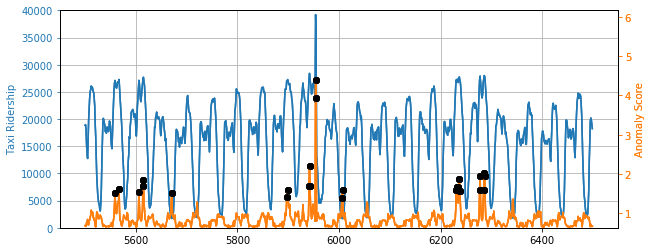

In [36]:
ax2.plot(anomalies.index, anomalies.score, 'ko')
fig

## Deletar endpoint

In [ ]:
sagemaker.Session().delete_endpoint(rcf_inference.endpoint)